In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
import mahotas
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C2"
DTYPE="CMMS"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C2_10,27,"[DATA/TRAINING/C2/C2_10/IMG_6566.HEIC, DATA/TR..."
1,C2_11,25,"[DATA/TRAINING/C2/C2_11/IMG_6666.HEIC, DATA/TR..."
2,C2_12,25,"[DATA/TRAINING/C2/C2_12/IMG_6789.HEIC, DATA/TR..."
3,C2_13,29,"[DATA/TRAINING/C2/C2_13/IMG_6944.HEIC, DATA/TR..."
4,C2_14,25,"[DATA/TRAINING/C2/C2_14/IMG_7189.HEIC, DATA/TR..."
5,C2_15,28,"[DATA/TRAINING/C2/C2_15/IMG_7315.HEIC, DATA/TR..."
6,C2_16,28,"[DATA/TRAINING/C2/C2_16/IMG_7447.HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16% IMG_7489.HEIC')

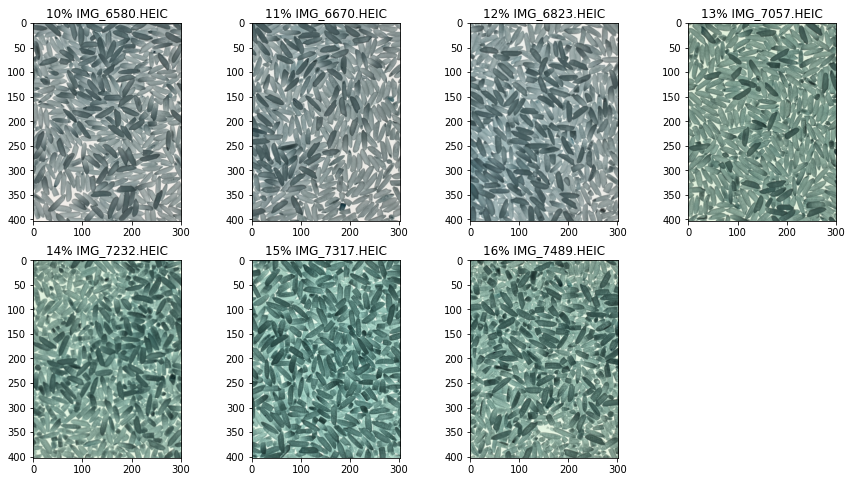

In [6]:
fig=plt.figure(figsize=(15, 8)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [7]:
def color_moments(image):
    # Split the channels - h,s,v
    h, s, v = cv2.split(image)
    # Initialize the color feature
    color_feature = []
    # N = h.shape[0] * h.shape[1]
    
    # The first central moment - average
    h_mean = np.mean(h)  # np.sum(h)/float(N)
    s_mean = np.mean(s)  # np.sum(s)/float(N)
    v_mean = np.mean(v)  # np.sum(v)/float(N)
    color_feature.extend([h_mean, s_mean, v_mean])
    
    # The second central moment - standard deviation
    h_std = np.std(h)  # np.sqrt(np.mean(abs(h - h.mean())**2))
    s_std = np.std(s)  # np.sqrt(np.mean(abs(s - s.mean())**2))
    v_std = np.std(v)  # np.sqrt(np.mean(abs(v - v.mean())**2))
    color_feature.extend([h_std, s_std, v_std])
    
    # The third central moment - the third root of the skewness
    h_skewness = np.mean(abs(h - h.mean())**3)
    s_skewness = np.mean(abs(s - s.mean())**3)
    v_skewness = np.mean(abs(v - v.mean())**3)
    h_thirdMoment = h_skewness**(1./3)
    s_thirdMoment = s_skewness**(1./3)
    v_thirdMoment = v_skewness**(1./3)
    color_feature.extend([h_thirdMoment, s_thirdMoment, v_thirdMoment])
    """
    # The second central moment - standard deviation
    hist_h = cv2.calcHist([h], [0], None, [256], [0, 256])
    hist_h = cv2.normalize(hist_h, hist_h, 0, 1, cv2.NORM_MINMAX)

    hist_s = cv2.calcHist([s], [0], None, [256], [0, 256])
    hist_s = cv2.normalize(hist_s, hist_s, 0, 1, cv2.NORM_MINMAX)

    hist_v = cv2.calcHist([v], [0], None, [256], [0, 256])
    hist_v = cv2.normalize(hist_v, hist_v, 0, 1, cv2.NORM_MINMAX)

    h_skew = kurtosis(hist_h)  
    s_skew = kurtosis(hist_s) 
    v_skew = kurtosis(hist_v) 
    color_feature.extend([h_skew[0], s_skew[0], v_skew[0]])
    
    
    h_kts = kurtosis(hist_h)  
    s_kts = kurtosis(hist_s) 
    v_kts = kurtosis(hist_v) 
    color_feature.extend([h_kts[0], s_kts[0], v_kts[0]])
    
    # The second central moment - standard deviation
    h_ent = entropy(hist_h)  
    s_ent = entropy(hist_s) 
    v_ent = entropy(hist_v) 
    color_feature.extend([h_ent, s_ent, v_ent])
    """
    return color_feature

In [153]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=25
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

        features = color_moments(hsv)
        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [154]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,scale,height,width,channels,IMAGENAME,HUMIDITY
0,32.149842,35.799601,141.179591,14.139441,20.056001,39.927919,22.474144,22.713244,47.458062,25,1008,756,3,IMG_6566.HEIC,10
1,36.056793,25.251062,146.522572,17.386732,13.504594,41.372094,25.146243,15.903463,49.905844,25,1008,756,3,IMG_6567.HEIC,10
2,30.946099,35.020297,147.616304,7.547239,16.769755,40.709146,11.939806,20.153062,49.147759,25,1008,756,3,IMG_6568.HEIC,10
3,35.123154,26.323966,145.913729,16.879688,14.018197,41.441973,24.853621,16.359458,49.711258,25,1008,756,3,IMG_6569.HEIC,10
4,31.670079,33.275064,146.711329,7.297241,14.888992,39.719919,11.231593,18.088711,48.286540,25,1008,756,3,IMG_6570.HEIC,10
5,32.744821,32.605479,145.980307,13.163047,18.184539,39.996653,20.316502,21.330844,48.309760,25,1008,756,3,IMG_6571.HEIC,10
6,32.563617,32.119886,147.339413,8.934311,14.216573,40.312563,13.826219,17.006878,48.525902,25,1008,756,3,IMG_6572.HEIC,10
7,32.361955,31.503466,144.497824,12.915661,15.973787,41.421687,20.293161,18.259051,49.061992,25,1008,756,3,IMG_6573.HEIC,10
8,30.788316,36.174795,146.149201,7.467056,16.430100,40.303108,12.192765,19.248755,48.341763,25,1008,756,3,IMG_6574.HEIC,10
9,34.508674,28.576206,144.051396,15.734507,15.275397,41.754020,23.636109,17.594607,49.732363,25,1008,756,3,IMG_6575.HEIC,10


# Classification

In [155]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [156]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [157]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [158]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [159]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [160]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.736842,0.788095,0.738095,0.762276,CMMS,C2,RF_C,25,1008,756,3
1,2,0.684211,0.764286,0.642857,0.698332,CMMS,C2,RF_C,25,1008,756,3
2,3,0.736842,0.776190,0.738095,0.756664,CMMS,C2,RF_C,25,1008,756,3
3,4,0.631579,0.583333,0.619048,0.600660,CMMS,C2,RF_C,25,1008,756,3
4,5,0.421053,0.559524,0.404762,0.469724,CMMS,C2,RF_C,25,1008,756,3
5,6,0.684211,0.761905,0.666667,0.711111,CMMS,C2,RF_C,25,1008,756,3
6,7,0.578947,0.595238,0.547619,0.570437,CMMS,C2,RF_C,25,1008,756,3
7,8,0.611111,0.678571,0.642857,0.660232,CMMS,C2,RF_C,25,1008,756,3
8,9,0.388889,0.461905,0.380952,0.417541,CMMS,C2,RF_C,25,1008,756,3
9,10,0.555556,0.690476,0.547619,0.610806,CMMS,C2,RF_C,25,1008,756,3


In [161]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,CMMS,C2,RF_C,0.602924,0.592857,0.625778,0.665952


### MLP Classifier

In [162]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [163]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [164]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.421053,0.392857,0.404762,0.398721,CMMS,C2,MLP_C,25,1008,756,3
1,2,0.789474,0.859524,0.785714,0.820963,CMMS,C2,MLP_C,25,1008,756,3
2,3,0.473684,0.533333,0.452381,0.489533,CMMS,C2,MLP_C,25,1008,756,3
3,4,0.736842,0.845238,0.690476,0.760059,CMMS,C2,MLP_C,25,1008,756,3
4,5,0.578947,0.509524,0.595238,0.549056,CMMS,C2,MLP_C,25,1008,756,3
5,6,0.315789,0.440476,0.285714,0.346604,CMMS,C2,MLP_C,25,1008,756,3
6,7,0.368421,0.511905,0.357143,0.420744,CMMS,C2,MLP_C,25,1008,756,3
7,8,0.611111,0.738095,0.642857,0.687192,CMMS,C2,MLP_C,25,1008,756,3
8,9,0.500000,0.523810,0.523810,0.523810,CMMS,C2,MLP_C,25,1008,756,3
9,10,0.611111,0.652381,0.619048,0.635277,CMMS,C2,MLP_C,25,1008,756,3


In [165]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,CMMS,C2,MLP_C,0.540643,0.535714,0.563196,0.600714


### XGBoost Classifier

In [166]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [167]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.578947,0.607143,0.571429,0.588745,CMMS,C2,XGB_C,25,1008,756,3
1,2,0.526316,0.466667,0.547619,0.503912,CMMS,C2,XGB_C,25,1008,756,3
2,3,0.421053,0.385714,0.428571,0.406015,CMMS,C2,XGB_C,25,1008,756,3
3,4,0.736842,0.773810,0.714286,0.742857,CMMS,C2,XGB_C,25,1008,756,3
4,5,0.526316,0.702381,0.523810,0.600092,CMMS,C2,XGB_C,25,1008,756,3
5,6,0.473684,0.488095,0.476190,0.482069,CMMS,C2,XGB_C,25,1008,756,3
6,7,0.578947,0.630952,0.571429,0.599717,CMMS,C2,XGB_C,25,1008,756,3
7,8,0.555556,0.619048,0.619048,0.619048,CMMS,C2,XGB_C,25,1008,756,3
8,9,0.555556,0.583333,0.595238,0.589226,CMMS,C2,XGB_C,25,1008,756,3
9,10,0.611111,0.735714,0.642857,0.686158,CMMS,C2,XGB_C,25,1008,756,3


In [168]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,CMMS,C2,XGB_C,0.556433,0.569048,0.581784,0.599286


# External validation

In [169]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C2_10,5,"[DATA/TEST/C2/C2_10/IMG_6560.HEIC, DATA/TEST/C..."
1,C2_11,5,"[DATA/TEST/C2/C2_11/IMG_6656.HEIC, DATA/TEST/C..."
2,C2_12,5,"[DATA/TEST/C2/C2_12/IMG._6813.HEIC, DATA/TEST/..."
3,C2_13,5,"[DATA/TEST/C2/C2_13/IMG_6918.HEIC, DATA/TEST/C..."
4,C2_14,5,"[DATA/TEST/C2/C2_14/IMG_7179.HEIC, DATA/TEST/C..."
5,C2_15,5,"[DATA/TEST/C2/C2_15/IMG_7305.HEIC, DATA/TEST/C..."
6,C2_16,5,"[DATA/TEST/C2/C2_16/IMG_7437.HEIC, DATA/TEST/C..."


In [170]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [171]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
        features = color_moments(hsv)
        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [172]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,scale,height,width,channels,IMAGENAME,HUMIDITY
0,30.920732,34.362959,143.612873,11.102689,15.997779,39.229799,18.797880,17.942966,46.214299,25,1008,756,3,IMG_6560.HEIC,10
1,32.256252,30.339148,140.279257,11.916211,14.775167,37.761540,19.659472,16.546971,44.889891,25,1008,756,3,IMG_6561.HEIC,10
2,29.101288,42.022838,140.419628,7.373561,18.733092,39.445073,12.988952,21.196035,46.587050,25,1008,756,3,IMG_6563.HEIC,10
3,28.383465,42.451074,141.989770,6.772915,16.769326,38.855493,13.049057,19.111547,45.070828,25,1008,756,3,IMG_6564.HEIC,10
4,30.662330,36.673780,141.121387,11.934428,17.818424,40.524246,19.643739,20.438069,47.958405,25,1008,756,3,IMG_6565.HEIC,10
0,40.400148,19.827924,146.157036,18.706306,10.584746,39.597346,25.908947,14.674564,49.030247,25,1008,756,3,IMG_6656.HEIC,11
1,38.134582,21.277076,144.994002,17.731072,10.879418,39.162153,25.320612,14.379965,48.942644,25,1008,756,3,IMG_6658.HEIC,11
2,31.687025,31.411214,142.413288,11.681349,15.297017,39.247428,19.228351,17.719445,47.163415,25,1008,756,3,IMG_6660.HEIC,11
3,36.092898,25.529478,146.380904,15.694338,13.004345,40.463712,22.415537,17.063464,49.023749,25,1008,756,3,IMG_6661.HEIC,11
4,30.392835,36.143478,141.869415,8.322688,15.835987,40.113031,14.279715,18.239463,46.911061,25,1008,756,3,IMG_6664.HEIC,11


In [173]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [174]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [175]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [176]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [177]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.00      0.00      0.00         5
     Class 1       0.50      0.40      0.44         5
     Class 2       0.38      1.00      0.56         5
     Class 3       0.50      0.60      0.55         5
     Class 4       0.50      0.20      0.29         5
     Class 5       1.00      0.20      0.33         5
     Class 6       0.44      0.80      0.57         5

    accuracy                           0.46        35
   macro avg       0.48      0.46      0.39        35
weighted avg       0.48      0.46      0.39        35



## MLP

In [178]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [179]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.00      0.00      0.00         5
     Class 1       1.00      0.40      0.57         5
     Class 2       0.38      1.00      0.56         5
     Class 3       0.56      1.00      0.71         5
     Class 4       0.50      0.40      0.44         5
     Class 5       0.40      0.40      0.40         5
     Class 6       1.00      0.40      0.57         5

    accuracy                           0.51        35
   macro avg       0.55      0.51      0.47        35
weighted avg       0.55      0.51      0.47        35



## XGBC

In [180]:
y_pred = modelXGBC.predict(X_test_scale) 

In [181]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.00      0.00      0.00         5
     Class 1       0.50      0.40      0.44         5
     Class 2       0.42      1.00      0.59         5
     Class 3       0.50      0.60      0.55         5
     Class 4       0.33      0.20      0.25         5
     Class 5       1.00      0.40      0.57         5
     Class 6       0.50      0.80      0.62         5

    accuracy                           0.49        35
   macro avg       0.46      0.49      0.43        35
weighted avg       0.46      0.49      0.43        35

